# Cross-Encoder Reranking

Unlike the bi-encoder used for broad search in dense retrieval unsing precomputed embeddings of the search texts, the cross-encoder processes each query and search text jointly without precomputing to achieve more precise ranking results at higher computational costs/ query latency. The cross-encoder will be used to rerank the top-20 hybrid candidates.

In [2]:
# %pip install -U sentence-transformers # Run only the first time using a new virtual environment

In [3]:
import time
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sentence_transformers import CrossEncoder

/Users/samulepisto/Sebrain/04_projects/study/data-science/NLP/project/semantic-search/semantic-product-search/.venv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1103 00:03:32.320000 39440 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


In [4]:
# ensure that code runs on GPU if available, otherwise fallback to CPU
if torch.backends.mps.is_available():
    device = "mps"
elif torch.cuda.is_available():
    device = "cuda"
else:
    device = "cpu"
print(f"PyTorch version: {torch.__version__}")
print(f"Using device: {device}")

PyTorch version: 2.15.0
Using device: mps


## 1 Data loading

In [5]:
# Catalog
catalog = pd.read_csv('../data/clean/catalog_clean.csv')
catalog = catalog.drop_duplicates(subset=['product_number']).reset_index(drop=True)
catalog['search_text'] = catalog['search_text'].fillna(catalog['clean_label']).fillna('')

In [6]:
# Query set
dev = pd.read_csv('../data/clean/test_set_dev.csv',)

# Group dev set by unique query so each query has a set of acceptable gold product numbers
dev_queries = dev.groupby('clean_query').agg({
    'gold_product_number': lambda x: set(str(p) for p in x),
    'area_name': 'first',
    'request': 'first'
}).reset_index()
print(f"Catalog unique products: {len(catalog):,}")
print(f"Development unique queries: {len(dev_queries):,}")

dev_queries[['clean_query', 'area_name']].head(3)

Catalog unique products: 70,720
Development unique queries: 136


,clean_query,area_name
0,11. akkuruuviväännin – 18 v,Koneet
1,"7. akkuruuviväännin – 10,9 v",Koneet
2,adblue 10 l,"Tekniset kemikaalit/-tarvikkeet, teipit"


In [7]:
# Load generated candidates from hybrid search
hybrid_rankings = pd.read_csv('../data/clean/hybrid_rrf_top20_dev.csv')
hybrid_rankings = hybrid_rankings.rename(columns={'rank': 'hybrid_rank'})

# Join search text on candidate products
hybrid_candidates = hybrid_rankings.merge(
    catalog[['product_number', 'search_text']],
    on='product_number',
    how='left'
)

print(f"Hybrid candidate rows: {len(hybrid_candidates):,}")
hybrid_candidates.head(3)

Hybrid candidate rows: 2,720


,clean_query,hybrid_rank,product_number,clean_label,search_text
0,11. akkuruuviväännin – 18 v,1,9999088795,käsine eureka 18-5 supercool harmaa 11,käsine eureka 18-5 supercool harmaa 11
1,11. akkuruuviväännin – 18 v,2,5701900001,konepaketti m-cube w-connect 18v maxi1,konepaketti m-cube w-connect 18v maxi1 sisältä...
2,11. akkuruuviväännin – 18 v,3,5705812000,akkulaturi alg 18/12,akkulaturi alg 18/12 alg 18 v m-cube -laturi o...


## 2 Evaluation function

In [8]:
def evaluate_method(method_name, search_func):
    """
    search_func(query_text) -> list of top-10 product numbers.
    Computes Hit@1, Recall@5, Recall@10, MRR, nDCG@5 and Latency.
    """
    t0 = time.time()
    hit1_count = 0
    hit5_count = 0
    hit10_count = 0
    rr_list = []
    ndcg5_list = []
    
    for _, row in dev_queries.iterrows():
        query = row['clean_query']
        gold_set = row['gold_product_number']
        
        # Retrieve top 10
        top_results = search_func(query)
        
        # Hit@1
        if len(top_results) > 0 and top_results[0] in gold_set:
            hit1_count += 1
            
        # Recall@5 and Recall@10
        if any(prod in gold_set for prod in top_results[:5]):
            hit5_count += 1
        if any(prod in gold_set for prod in top_results[:10]):
            hit10_count += 1
            
        # MRR
        rr = 0.0
        for rank, prod in enumerate(top_results[:10], start=1):
            if prod in gold_set:
                rr = 1.0 / rank
                break
        rr_list.append(rr)
        
        # nDCG@5
        dcg = sum(1.0 / np.log2(i + 1) for i, prod in enumerate(top_results[:5], start=1) if prod in gold_set)
        ideal_hits = min(len(gold_set), 5)
        idcg = sum(1.0 / np.log2(i + 1) for i in range(1, ideal_hits + 1))
        ndcg5 = (dcg / idcg) if idcg > 0 else 0.0
        ndcg5_list.append(ndcg5)
        
    elapsed = time.time() - t0
    n = len(dev_queries)
    
    return {
        'Method': method_name,
        'Hit@1': hit1_count / n,
        'Recall@5': hit5_count / n,
        'Recall@10': hit10_count / n,
        'MRR': np.mean(rr_list),
        'nDCG@5': np.mean(ndcg5_list),
        'Latency (ms/query)': (elapsed / n) * 1000
    }

## 3 Model loading and reranking

Rerank 20 candidates retrieved through hybrid retrival using `BAAI/bge-reranker-v2-m3`.

In [9]:
# Load cross-encoder model
model_name = "BAAI/bge-reranker-v2-m3"
print(f"Loading cross-encoder '{model_name}' on {device}...")
reranker = CrossEncoder(model_name,device=device,max_length=512)
print("Cross-encoder loaded.")

Loading cross-encoder 'BAAI/bge-reranker-v2-m3' on mps...


Loading weights: 100%|██████████| 393/393 [00:00<00:00, 7792.20it/s]


Cross-encoder loaded.


In [10]:
# Reranking function
def rerank_candidates(query_text, top_k=10):
    # Filter to 20 relevant candidates
    query_candidates = hybrid_candidates[
        hybrid_candidates['clean_query'] == query_text
    ].copy()

    # Build pairs of query text and search text
    query_product_pairs = [
        (query_text, search_text)
        for search_text in query_candidates['search_text']
    ]

    # Calculate and add cross-encoder scores
    query_candidates['reranker_score'] = reranker.predict(
        query_product_pairs,
        batch_size=4,
        show_progress_bar=False
    )

    # Sort by cross-encoder score. If tied by hybrid rank and reset index
    query_candidates = query_candidates.sort_values(
        by=['reranker_score', 'hybrid_rank'],
        ascending=[False, True]
    ).reset_index(drop=True)

    # Return top k product numbers in relevant order as list
    return query_candidates['product_number'].head(top_k).tolist()

Development-set evaluation

In [11]:
# Evaluate cross-encoder reranking on development queries
print(f"Evaluating Cross-Encoder Reranking on {len(dev_queries)} dev queries...")
reranker_eval = evaluate_method(
    "Cross-Encoder (bge-reranker-v2-m3)",
    rerank_candidates
)

# Display results
reranker_df = pd.DataFrame([reranker_eval])
reranker_df.round({
    'Hit@1': 4,
    'Recall@5': 4,
    'Recall@10': 4,
    'MRR': 4,
    'nDCG@5': 4,
    'Latency (ms/query)': 1
})

Evaluating Cross-Encoder Reranking on 136 dev queries...


,Method,Hit@1,Recall@5,Recall@10,MRR,nDCG@5,Latency (ms/query)
0,Cross-Encoder (bge-reranker-v2-m3),0.3309,0.5147,0.5809,0.4131,0.4277,1141.3


## 4 Comparison with Hybrid RRF

Load the saved Hybrid RRF results from notebook 06 and append the cross-encoder reranking results. The cross-encoder latency represents the additional reranking stage after the hybrid candidates are available.

In [12]:
# Load Hybrid RRF results from notebook 06
with open('../data/clean/hybrid_rrf_results.json', 'r', encoding='utf-8') as f:
    hybrid_data = json.load(f)
hybrid_df = pd.DataFrame(hybrid_data['results'])
hybrid_df = hybrid_df[hybrid_df['Method'] == hybrid_data['selected_method']]

# Combine hybrid and reranking results
comparison_df = pd.concat([hybrid_df, reranker_df], ignore_index=True)
display_cols = [
    'Method', 'Hit@1', 'Recall@5', 'Recall@10',
    'MRR', 'nDCG@5', 'Latency (ms/query)'
]
comparison_df[display_cols].round({
    'Hit@1': 4,
    'Recall@5': 4,
    'Recall@10': 4,
    'MRR': 4,
    'nDCG@5': 4,
    'Latency (ms/query)': 1
})

,Method,Hit@1,Recall@5,Recall@10,MRR,nDCG@5,Latency (ms/query)
0,Hybrid RRF (k=60),0.2279,0.3824,0.5147,0.3074,0.3118,3.6
1,Cross-Encoder (bge-reranker-v2-m3),0.3309,0.5147,0.5809,0.4131,0.4277,1141.3


## 5 Comparison plot

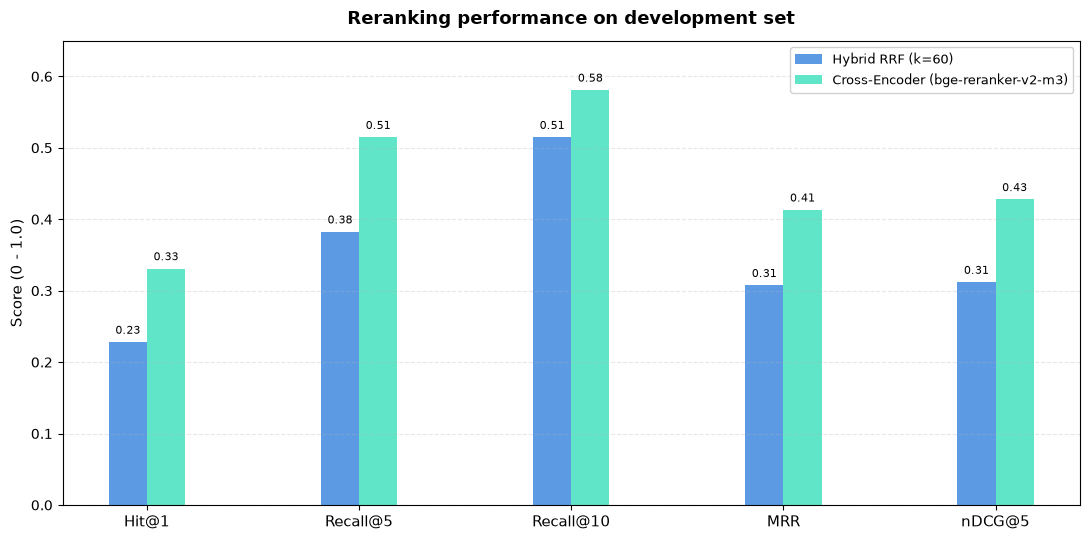

In [13]:
# Plot comparison of retrieval metrics across all methods
plt.style.use('default')
metrics = ['Hit@1', 'Recall@5', 'Recall@10', 'MRR', 'nDCG@5']
methods = comparison_df['Method'].tolist()
n_methods = len(methods)

x = np.arange(len(metrics))
width = 0.18

fig, ax = plt.subplots(figsize=(11, 5.5))
colors = ['#4A90E2', '#50E3C2', '#F5A623', '#9013FE']

for i, row in comparison_df.iterrows():
    vals = [row[m] for m in metrics]
    bars = ax.bar(x + (i - (n_methods - 1) / 2) * width, vals, width, label=row['Method'], color=colors[i % len(colors)], alpha=0.9)
    # Add data labels
    for bar in bars:
        h = bar.get_height()
        ax.text(bar.get_x() + bar.get_width() / 2, h + 0.008, f"{h:.2f}", ha='center', va='bottom', fontsize=8, rotation=0)

ax.set_ylabel('Score (0 - 1.0)', fontsize=11)
ax.set_title('Reranking performance on development set', fontsize=13, fontweight='bold', pad=12)
ax.set_xticks(x)
ax.set_xticklabels(metrics, fontsize=11)
ax.set_ylim(0, 0.65)
ax.legend(frameon=True, facecolor='white', framealpha=0.9, fontsize=9.5)
ax.grid(axis='y', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

Evaluation by category

In [14]:
# evaluate query hits per category for selected methods
cat_records = []

# load previous retrieval category records from hybrid_retrieval_results.json
cat_records.extend(hybrid_data['top_categories_breakdown'])

# evaluate hybrid RRF by category
for _, row in dev_queries.iterrows():
    top_results = rerank_candidates(row['clean_query'])
    gold_set = row['gold_product_number']
    hit1 = int(len(top_results) > 0 and top_results[0] in gold_set)
    recall5 = int(any(product in gold_set for product in top_results[:5]))
    cat_records.append({
        'Method': 'Cross-Encoder (bge-reranker-v2-m3)',
        'area_name': row['area_name'],
        'Hit@1': float(hit1),
        'Recall@5': float(recall5)
    })

df_cat = pd.DataFrame(cat_records)
selected_category_methods = [
    'Hybrid RRF (k=60)',
    'Cross-Encoder (bge-reranker-v2-m3)'
]
df_cat = df_cat[df_cat['Method'].isin(selected_category_methods)]
top_cats = dev_queries['area_name'].value_counts().head(5).index

# summary tables
cat_table_h1 = df_cat[df_cat['area_name'].isin(top_cats)].groupby(
    ['area_name', 'Method']
)['Hit@1'].mean().unstack('Method')
cat_table_r5 = df_cat[df_cat['area_name'].isin(top_cats)].groupby(
    ['area_name', 'Method']
)['Recall@5'].mean().unstack('Method')

print("Hit@1 by Category:")
display(cat_table_h1.round(3))

print("\nRecall@5 by Category:")
display(cat_table_r5.round(3))

Hit@1 by Category:


Method,Cross-Encoder (bge-reranker-v2-m3),Hybrid RRF (k=60)
area_name,,
Kiinnitystarvikkeet,0.000,0.083
Käsityökalut,0.290,0.323
Materiaalin mekaaninen työstö,0.333,0.143
"Tekniset kemikaalit/-tarvikkeet, teipit",0.429,0.143
Työturvallisuus,0.214,0.143



Recall@5 by Category:


Method,Cross-Encoder (bge-reranker-v2-m3),Hybrid RRF (k=60)
area_name,,
Kiinnitystarvikkeet,0.083,0.083
Käsityökalut,0.613,0.581
Materiaalin mekaaninen työstö,0.476,0.333
"Tekniset kemikaalit/-tarvikkeet, teipit",0.571,0.286
Työturvallisuus,0.321,0.214


**Conclusion**

Reranking results using `BAAI/bge-reranker-v2-m3` improves every overall metric. With reranking, especially performance gains in Hit@1 MRR and nDCG@5 are relevant, as this step of the pipeline is focused on ranking relevant products as high as possible, that have already been retrieved.

As for the evaluation by category, almost all metrics showed clear improvements, too. Only Hit@1 for hand tools did slightly decrease, however their Recall@5 improved at the same time.

As the latency was measured to be below 1 second, the performance gains clearly justify the additional compute.

In [15]:
# Export results
output_path = '../data/clean/reranking_results.json'

cat_summary_records = df_cat[
    df_cat['area_name'].isin(top_cats)
].groupby(['area_name', 'Method'])[[
    'Hit@1', 'Recall@5'
]].mean().round(3).reset_index().to_dict(orient='records')

export_data = {
    'model_name': model_name,
    'candidate_source': 'Hybrid RRF (k=60) top 20',
    'results': comparison_df.to_dict(orient='records'),
    'top_categories_breakdown': cat_summary_records
}

with open(output_path, 'w', encoding='utf-8') as file:
    json.dump(export_data, file, indent=2, ensure_ascii=False)

print(f"Results successfully saved to '{output_path}'")

Results successfully saved to '../data/clean/reranking_results.json'


In [16]:
rerank_records = []

print(f"Loading rerank logs... for {len(dev_queries)} queries")

for _, row in dev_queries.iterrows():
    q = row['clean_query']
    gold = row['gold_product_number']

    # hybrid candidates for this query
    q_cands = hybrid_candidates[hybrid_candidates['clean_query'] == q].copy()
    pairs = [(q, text) for text in q_cands['search_text']]

    # rerank the candidates
    q_cands['reranker_score'] = reranker.predict(pairs, show_progress_bar=False)
    q_cands = q_cands.sort_values(by=['reranker_score', 'hybrid_rank'], ascending=[False, True]).reset_index(drop=True)

    # record the reranked results
    for rank, r_row in q_cands.iterrows():
        p_num = str(r_row['product_number'])
        rerank_records.append({
            'clean_query': q,
            'rank': rank + 1,
            'product_number': p_num,
            'clean_label': r_row['clean_label'],
            'reranker_score': round(float(r_row['reranker_score']), 4),
            'is_hit': p_num in gold
        })

df_rerank_log = pd.DataFrame(rerank_records)
output_log_path = '../data/clean/reranked_top20_dev.csv'
df_rerank_log.to_csv(output_log_path, index=False)
print(f"Reranking-log saved to: '{output_log_path}' ({len(df_rerank_log)} records)")

Loading rerank logs... for 136 queries
Reranking-log saved to: '../data/clean/reranked_top20_dev.csv' (2720 records)
